# Regularization test

The learning curves showed overfitting: models nearly memorize their training data while error on unseen days gets worse. This tests fixed ways of limiting that, using the unified models as the control, with early stopping kept on. Walk-forward is the main evidence, and 80/10/10 is a second view. The test split stays locked.

| Candidate | Change | Models |
| --- | --- | --- |
| Dropout 0.2 | Mild dropout in the recurrent layer | RNN, LSTM |
| Dropout 0.5 | Strong dropout in the recurrent layer | RNN, LSTM |
| L2 0.0001 | Mild weight penalty | RNN, LSTM |
| L2 0.001 | Stronger weight penalty | RNN, LSTM |
| Smaller network | 16 recurrent units and Dense(8) | RNN, LSTM |
| 2-layer | Layers of 64 and 32 units, as a test of depth | LSTM |
| Stronger | Depth 2, learning rate 0.02, row and column sampling 0.5, `reg_lambda` 10, `min_child_weight` 10 | XGBoost |

**Real progress** means correlation clearly above zero, an R² interval reaching or crossing zero, and direction closer to or above always-up. Wider predictions, or better MSE from flatter predictions, aren't enough. With this many candidates a lucky winner is possible, so a winner needs a 5-seed rerun before it's trusted.

All runs use 3 seeds, common dates, standardization and the 1-day horizon.

In [1]:
from pathlib import Path
import sys

import pandas as pd

# notebook is in training/benchmarking/notebooks, parents[1] points to training/
sys.path.insert(0, str(Path.cwd().parents[1]))

from benchmarking.regularization import (
    compare_to_control,
    for_base_model,
    run_regularization_split,
    run_regularization_walk_forward,
    split_model_names,
    with_control,
)
from benchmarking.result_plots import (
    TRACK_TITLES,
    plot_split_results,
    plot_track_comparisons,
    plot_walk_forward_intervals,
)
from benchmarking.walk_forward import (
    TRACK_COMPARISONS,
    compare_tracks,
    correlation_intervals,
    score_walk_forward,
    walk_forward_intervals,
)

RESULTS_DIR = Path.cwd().parent / "results"

pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 100, "display.float_format", "{:.4f}".format)

## Training

1,296 fits, or 96 per candidate and model on walk-forward and 12 on 80/10/10. Saved work is skipped, so this finishes quickly once everything is saved. Delete the `regularization_*` files in `results/` to retrain after changing any settings.

In [2]:
run_regularization_walk_forward(RESULTS_DIR / "regularization_walk_forward_predictions.csv")
run_regularization_split(
    RESULTS_DIR / "regularization_split_seed_metrics.csv",
    RESULTS_DIR / "regularization_split_predictions.csv",
)

## Load saved results

Run this and the setup cell to use any cell below without retraining. The control uses the same 3 seeds.

In [3]:
walk_forward = with_control(
    pd.read_csv(RESULTS_DIR / "regularization_walk_forward_predictions.csv"),
    pd.read_csv(RESULTS_DIR / "unified_walk_forward_predictions.csv"),
)
split_metrics = with_control(
    pd.read_csv(RESULTS_DIR / "regularization_split_seed_metrics.csv"),
    pd.read_csv(RESULTS_DIR / "unified_split_seed_metrics.csv"),
)
split_predictions = with_control(
    pd.read_csv(RESULTS_DIR / "regularization_split_predictions.csv"),
    pd.read_csv(RESULTS_DIR / "unified_split_predictions.csv"),
)
split_validation = split_predictions[split_predictions["split"] == "validation"]


def scale_mse(table, columns):
    """Show tiny MSE values multiplied by 10,000."""
    return table.assign(**{column: table[column] * 1e4 for column in columns})

## Walk-forward

### Walk-forward: results with confidence intervals

781 scored days. `oos_r2` is R² against the train-mean baseline. MSE values are shown multiplied by 10,000.

In [4]:
intervals = walk_forward_intervals(walk_forward)
intervals.to_csv(RESULTS_DIR / "regularization_walk_forward_intervals.csv", index=False)
scale_mse(intervals, ["mse", "baseline_mse"]).drop(columns=["horizon", "days"])

,track,model,mse,baseline_mse,oos_r2,oos_r2_lower,oos_r2_upper,directional_accuracy,always_up_accuracy,direction_edge,direction_edge_lower,direction_edge_upper
0,no_news_no_feature_engineering,RNN | Control,11.9943,11.5200,-0.0412,-0.0780,-0.0093,0.5327,0.5493,-1.6645,-5.4641,2.4328
1,no_news_no_feature_engineering,LSTM | Control,11.7596,11.5200,-0.0208,-0.0416,-0.0032,0.4998,0.5493,-4.9509,-8.9202,-1.5365
2,no_news_no_feature_engineering,XGBoost | Control,11.8449,11.5200,-0.0282,-0.0493,-0.0098,0.5241,0.5493,-2.5181,-5.0363,-0.1707
3,no_news_with_feature_engineering,RNN | Control,12.0608,11.5200,-0.0469,-0.0856,-0.0131,0.5271,0.5493,-2.2194,-5.5484,0.8963
4,no_news_with_feature_engineering,LSTM | Control,11.9640,11.5200,-0.0385,-0.0740,-0.0102,0.4904,0.5493,-5.8899,-10.1601,-2.3474
5,no_news_with_feature_engineering,XGBoost | Control,11.8686,11.5200,-0.0303,-0.0541,-0.0096,0.5271,0.5493,-2.2194,-5.2081,0.2998
6,news_with_feature_engineering,RNN | Control,12.3470,11.5200,-0.0718,-0.1086,-0.0418,0.5160,0.5493,-3.3291,-6.3604,-0.2561
7,news_with_feature_engineering,LSTM | Control,11.9256,11.5200,-0.0352,-0.0532,-0.0180,0.5245,0.5493,-2.4755,-5.9752,0.4706
8,news_with_feature_engineering,XGBoost | Control,11.8409,11.5200,-0.0279,-0.0429,-0.0147,0.4994,0.5493,-4.9936,-7.5117,-2.6462
9,news_with_feature_engineering_and_tech,RNN | Control,12.4466,11.5200,-0.0804,-0.1254,-0.0425,0.5207,0.5493,-2.8596,-6.7008,0.8131


### Walk-forward: RNN candidates

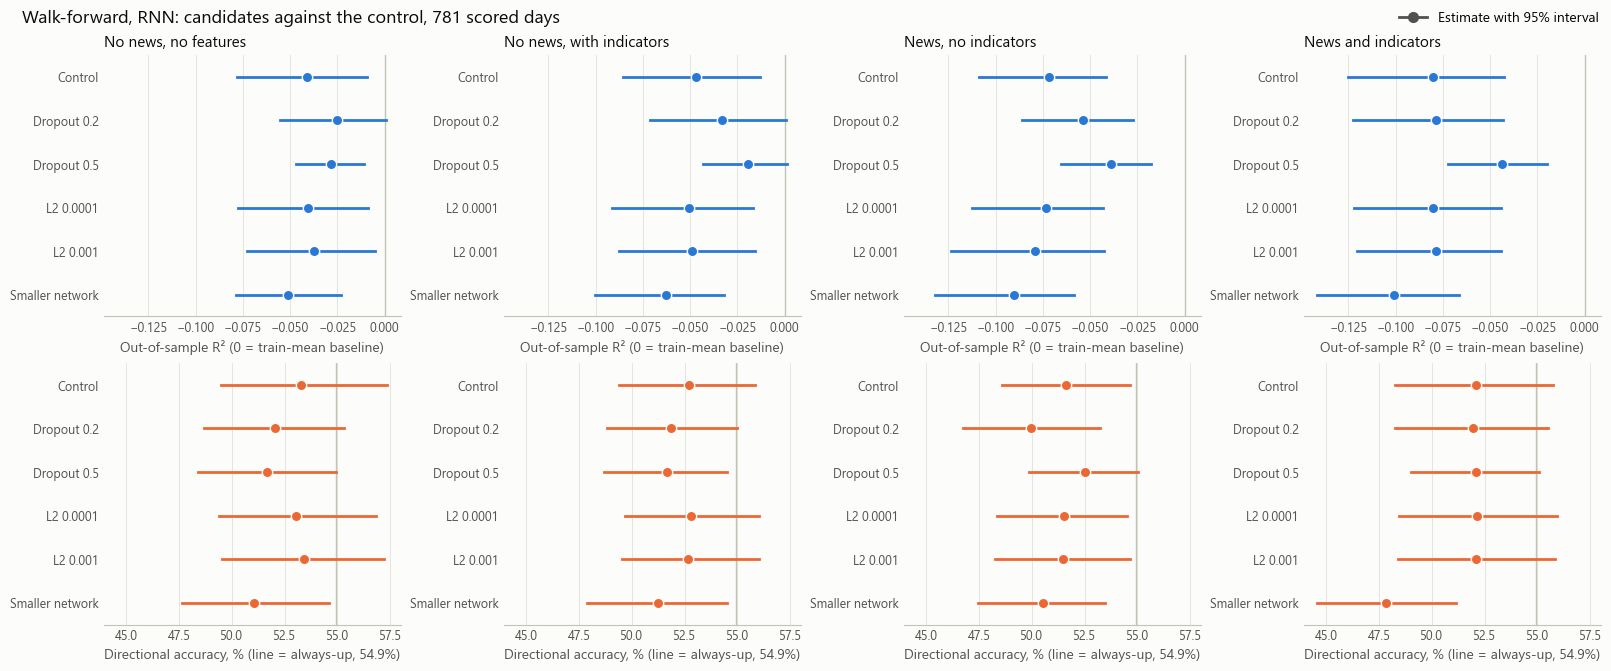

In [5]:
plot_walk_forward_intervals(
    for_base_model(intervals, "RNN"),
    title="Walk-forward, RNN: candidates against the control, 781 scored days",
)

### Walk-forward: LSTM candidates

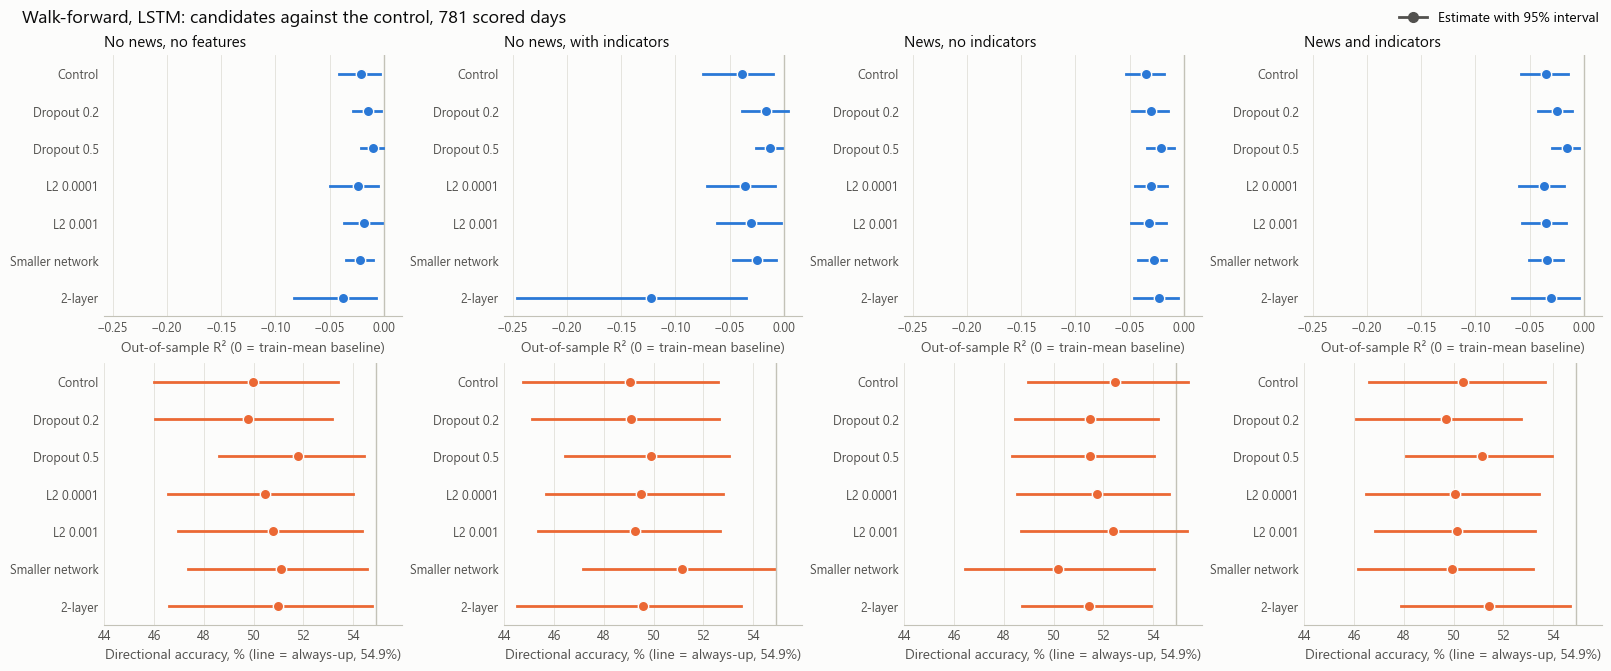

In [6]:
plot_walk_forward_intervals(
    for_base_model(intervals, "LSTM"),
    title="Walk-forward, LSTM: candidates against the control, 781 scored days",
)

### Walk-forward: XGBoost candidates

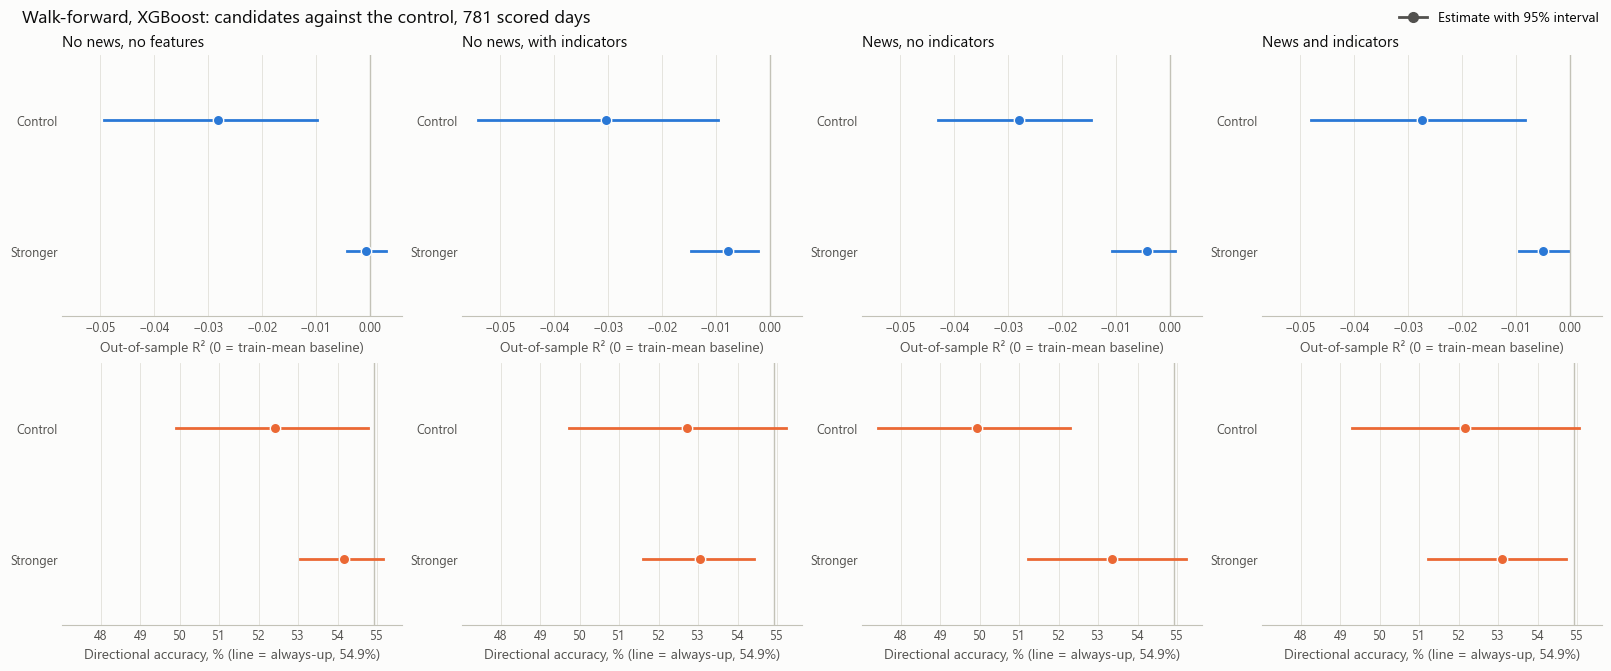

In [7]:
plot_walk_forward_intervals(
    for_base_model(intervals, "XGBoost"),
    title="Walk-forward, XGBoost: candidates against the control, 781 scored days",
)

### Walk-forward: are predictions still flat, and is signal appearing?

This is the table for judging real progress. `correlation` is with actual returns, and `spread_ratio` is prediction spread divided by actual spread. `best_step` is the epoch or tree count used, and later values suggest models really train for longer. `share_at_limit` is how often a fit reached its maximum.

In [8]:
FIT_KEYS = ["track", "model", "seed", "round"]
fits = walk_forward.drop_duplicates(FIT_KEYS)
stopping = fits.assign(at_limit=fits["steps_run"] >= fits["model"].map(lambda name: 500 if name.startswith("XGBoost") else 200))
stopping = (
    stopping.groupby(["track", "model"], sort=False)
    .agg(best_step=("best_step", "mean"), share_at_limit=("at_limit", "mean"))
)
scores = score_walk_forward(walk_forward).groupby(["track", "model"], sort=False)[["correlation", "spread_ratio", "oos_r2"]].mean()
scores["share_predicted_up"] = (
    walk_forward.assign(up=walk_forward["predicted"] > 0).groupby(["track", "model"], sort=False)["up"].mean()
)
scores.join(stopping)

correlation  spread_ratio  oos_r2  share_predicted_up  best_step  share_at_limit
track                                  model                                                                                                   
no_news_no_feature_engineering         RNN | Control                0.0383        0.2489 -0.0412              0.6577     7.0417          0.0000
                                       LSTM | Control              -0.0013        0.1495 -0.0208              0.7350     8.0417          0.0000
                                       XGBoost | Control           -0.0534        0.1271 -0.0282              0.8203    31.6667          0.0000
no_news_with_feature_engineering       RNN | Control                0.0587        0.2814 -0.0469              0.5933     7.1250          0.0000
                                       LSTM | Control               0.0059        0.2000 -0.0385              0.6837     7.6250          0.0000
                                       XGBoost | Control           -0.0384        0.1412 -0.0303              0.8071    34.2500          0.0000
news_with_feature_engineering          RNN | Control                0.0085        0.2789 -0.0718              0.6044     6.0000          0.0000
                                       LSTM | Control              -0.0348        0.1547 -0.0352              0.6718     3.9167          0.0000
                                       XGBoost | Control           -0.0542        0.1220 -0.0279              0.8071    26.5417          0.0000
news_with_feature_engineering_and_tech RNN | Control                0.0411        0.3211 -0.0804              0.5621     5.0000          0.0000
                                       LSTM | Control              -0.0146        0.1719 -0.0348              0.6944     3.7083          0.0000
                                       XGBoost | Control           -0.0428        0.1331 -0.0275              0.7840    26.1667          0.0000
no_news_no_feature_engineering         RNN | Dropout 0.2            0.0372        0.2056 -0.0251              0.6816    11.1667          0.0000
                                       RNN | Dropout 0.5            0.0081        0.1819 -0.0283              0.6633    16.9167          0.0000
                                       RNN | L2 0.0001              0.0405        0.2525 -0.0406              0.6573     7.5833          0.0000
                                       RNN | L2 0.001               0.0419        0.2449 -0.0372              0.6586     6.9583          0.0000
                                       RNN | Smaller network        0.0490        0.2628 -0.0512              0.5672    13.0000          0.0000
                                       LSTM | Dropout 0.2          -0.0147        0.1154 -0.0146              0.7606    10.7500          0.0000
                                       LSTM | Dropout 0.5          -0.0291        0.0755 -0.0095              0.8007     8.2500          0.0000
                                       LSTM | L2 0.0001             0.0076        0.1665 -0.0237              0.7388     9.0000          0.0000
                                       LSTM | L2 0.001              0.0051        0.1466 -0.0179              0.7414     8.1667          0.0000
                                       LSTM | Smaller network      -0.0093        0.1381 -0.0215              0.6705    10.6250          0.0000
                                       LSTM | 2-layer              -0.0116        0.1807 -0.0373              0.7341     9.6667          0.0000
                                       XGBoost | Stronger          -0.0187        0.0346 -0.0006              0.9607    21.1250          0.0000
no_news_with_feature_engineering       RNN | Dropout 0.2            0.0660        0.2630 -0.0333              0.6325    13.6667          0.0000
                                       RNN | Dropout 0.5            0.0443        0.2002 -0.0194              0.6671    14.6667          0.0000
                               

### Walk-forward: correlation with confidence intervals

Clearly above zero is one of the progress criteria. Predictions are averaged across seeds per day first, so these values are higher than the seed averages in the table above. Sorted from highest to lowest.

In [9]:
correlations = correlation_intervals(walk_forward)
correlations.to_csv(RESULTS_DIR / "regularization_correlation_intervals.csv", index=False)
correlations.drop(columns="horizon").sort_values("correlation", ascending=False)

,track,model,correlation,correlation_lower,correlation_upper
24,no_news_with_feature_engineering,RNN | Dropout 0.2,0.0890,0.0134,0.1699
3,no_news_with_feature_engineering,RNN | Control,0.0873,0.0211,0.1561
27,no_news_with_feature_engineering,RNN | L2 0.001,0.0807,0.0198,0.1482
26,no_news_with_feature_engineering,RNN | L2 0.0001,0.0785,0.0167,0.1445
16,no_news_no_feature_engineering,RNN | Smaller network,0.0748,0.0038,0.1486
25,no_news_with_feature_engineering,RNN | Dropout 0.5,0.0675,0.0011,0.1355
51,news_with_feature_engineering_and_tech,RNN | L2 0.001,0.0632,0.0059,0.1234
50,news_with_feature_engineering_and_tech,RNN | L2 0.0001,0.0628,0.0023,0.1227
9,news_with_feature_engineering_and_tech,RNN | Control,0.0622,0.0012,0.1230
15,no_news_no_feature_engineering,RNN | L2 0.001,0.0569,-0.0268,0.1478


## Candidates against their control

The same input set and days, with each candidate compared with the control day by day. Positive differences favor the candidate. An interval that includes 0 means they can't be told apart.

### Against the control: table

MSE values are shown multiplied by 10,000.

In [10]:
control_comparisons = {
    base: compare_to_control(walk_forward, base) for base in ("RNN", "LSTM", "XGBoost")
}
all_control_comparisons = pd.concat([table.assign(base_model=base) for base, table in control_comparisons.items()], ignore_index=True)
all_control_comparisons.to_csv(RESULTS_DIR / "regularization_control_comparisons.csv", index=False)
scale_mse(all_control_comparisons, ["mse_first", "mse_second", "mse_improvement", "mse_improvement_lower", "mse_improvement_upper"]).drop(columns=["first_track", "second_track", "horizon", "days"])

,comparison,track,mse_first,mse_second,mse_improvement,mse_improvement_lower,mse_improvement_upper,accuracy_first,accuracy_second,direction_gain,direction_gain_lower,direction_gain_upper,base_model
0,Dropout 0.2 vs control,no_news_no_feature_engineering,11.8089,11.9943,0.1854,0.0465,0.3246,0.5203,0.5327,-1.2377,-2.9023,0.5548,RNN
1,Dropout 0.2 vs control,no_news_with_feature_engineering,11.9033,12.0608,0.1575,0.0044,0.3243,0.5186,0.5271,-0.8536,-2.5181,0.7682,RNN
2,Dropout 0.2 vs control,news_with_feature_engineering,12.1388,12.3470,0.2082,0.0596,0.3555,0.4998,0.5160,-1.6219,-3.2010,0.0854,RNN
3,Dropout 0.2 vs control,news_with_feature_engineering_and_tech,12.4260,12.4466,0.0206,-0.2196,0.2618,0.5194,0.5207,-0.1280,-1.6219,1.3658,RNN
4,Dropout 0.5 vs control,no_news_no_feature_engineering,11.8458,11.9943,0.1485,-0.1199,0.4051,0.5169,0.5327,-1.5792,-3.7559,0.6402,RNN
5,Dropout 0.5 vs control,no_news_with_feature_engineering,11.7438,12.0608,0.3170,0.0595,0.5799,0.5169,0.5271,-1.0243,-2.8596,0.8109,RNN
6,Dropout 0.5 vs control,news_with_feature_engineering,11.9704,12.3470,0.3766,0.1960,0.5476,0.5250,0.5160,0.8963,-1.1950,2.8169,RNN
7,Dropout 0.5 vs control,news_with_feature_engineering_and_tech,12.0241,12.4466,0.4225,0.1804,0.6786,0.5207,0.5207,0.0000,-2.1767,2.1340,RNN
8,L2 0.0001 vs control,no_news_no_feature_engineering,11.9878,11.9943,0.0065,-0.0583,0.0660,0.5305,0.5327,-0.2134,-0.9390,0.4695,RNN
9,L2 0.0001 vs control,no_news_with_feature_engineering,12.1046,12.0608,-0.0437,-0.0949,-0.0020,0.5280,0.5271,0.0854,-0.4695,0.6829,RNN


### Against the control: RNN

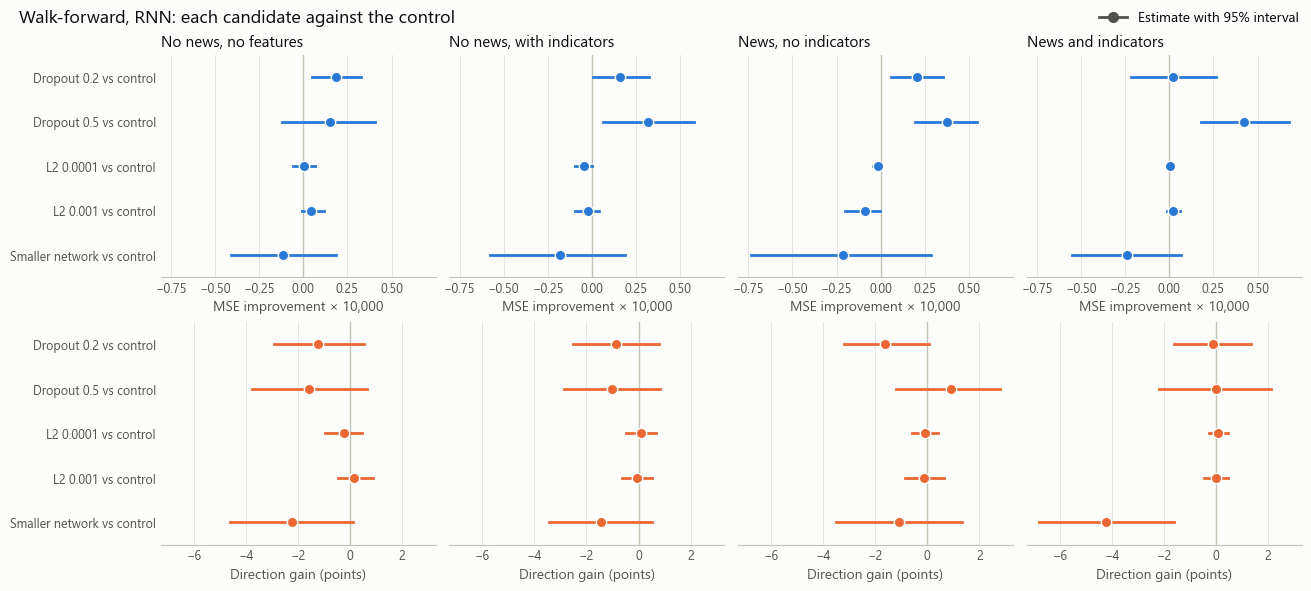

In [11]:
plot_track_comparisons(
    control_comparisons["RNN"].assign(model=control_comparisons["RNN"]["track"].map(TRACK_TITLES)),
    title="Walk-forward, RNN: each candidate against the control",
)

### Against the control: LSTM

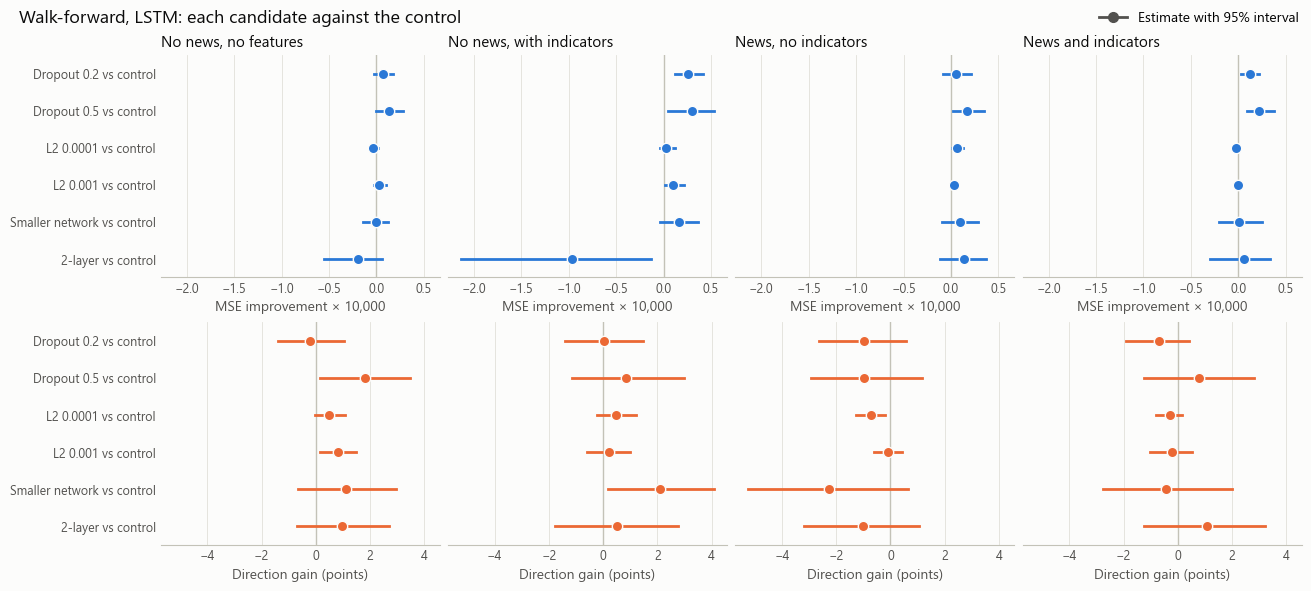

In [12]:
plot_track_comparisons(
    control_comparisons["LSTM"].assign(model=control_comparisons["LSTM"]["track"].map(TRACK_TITLES)),
    title="Walk-forward, LSTM: each candidate against the control",
)

### Against the control: XGBoost

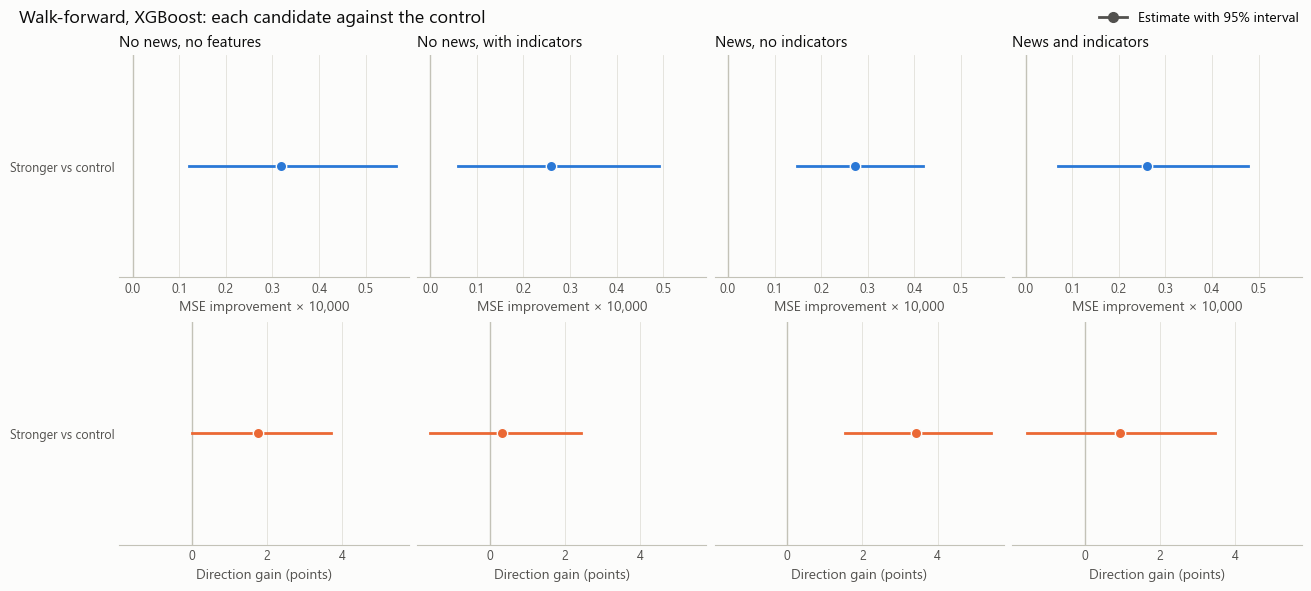

In [13]:
plot_track_comparisons(
    control_comparisons["XGBoost"].assign(model=control_comparisons["XGBoost"]["track"].map(TRACK_TITLES)),
    title="Walk-forward, XGBoost: each candidate against the control",
)

## News against no news, within each candidate

### News against no news: walk-forward

News, no indicators against no news, no features, where news is the only difference. Regularization might let news help where it couldn't before. Positive differences favor news. MSE values are shown multiplied by 10,000.

In [14]:
news_comparisons = compare_tracks(walk_forward, TRACK_COMPARISONS[:1])
news_comparisons.to_csv(RESULTS_DIR / "regularization_news_comparisons.csv", index=False)
scale_mse(news_comparisons, ["mse_first", "mse_second", "mse_improvement", "mse_improvement_lower", "mse_improvement_upper"]).drop(columns=["first_track", "second_track", "horizon", "days", "comparison"])

,model,mse_first,mse_second,mse_improvement,mse_improvement_lower,mse_improvement_upper,accuracy_first,accuracy_second,direction_gain,direction_gain_lower,direction_gain_upper
0,RNN | Control,12.3470,11.9943,-0.3527,-0.6890,-0.0376,0.5160,0.5327,-1.6645,-4.7386,1.3231
1,LSTM | Control,11.9256,11.7596,-0.1660,-0.4169,0.0826,0.5245,0.4998,2.4755,-0.1718,5.3777
2,XGBoost | Control,11.8409,11.8449,0.0040,-0.1361,0.1636,0.4994,0.5241,-2.4755,-4.1837,-0.7256
3,RNN | Dropout 0.2,12.1388,11.8089,-0.3299,-0.5900,-0.0907,0.4998,0.5203,-2.0487,-4.7802,0.5122
4,RNN | Dropout 0.5,11.9704,11.8458,-0.1246,-0.3657,0.1141,0.5250,0.5169,0.8109,-2.0487,3.7985
5,RNN | L2 0.0001,12.3638,11.9878,-0.3759,-0.7285,-0.0473,0.5152,0.5305,-1.5365,-4.6522,1.3658
6,RNN | L2 0.001,12.4344,11.9489,-0.4855,-0.8676,-0.1572,0.5147,0.5344,-1.9633,-5.0363,0.8536
7,RNN | Smaller network,12.5605,12.1094,-0.4511,-0.8257,-0.1003,0.5053,0.5105,-0.5122,-2.8169,1.8353
8,LSTM | Dropout 0.2,11.8702,11.6888,-0.1814,-0.3559,-0.0059,0.5147,0.4977,1.7072,-0.9816,4.8229
9,LSTM | Dropout 0.5,11.7612,11.6297,-0.1316,-0.2380,-0.0230,0.5147,0.5177,-0.2988,-2.6035,2.1351


## 80/10/10 split

The 123 validation days, which aren't used for early stopping.

### 80/10/10: RNN candidates

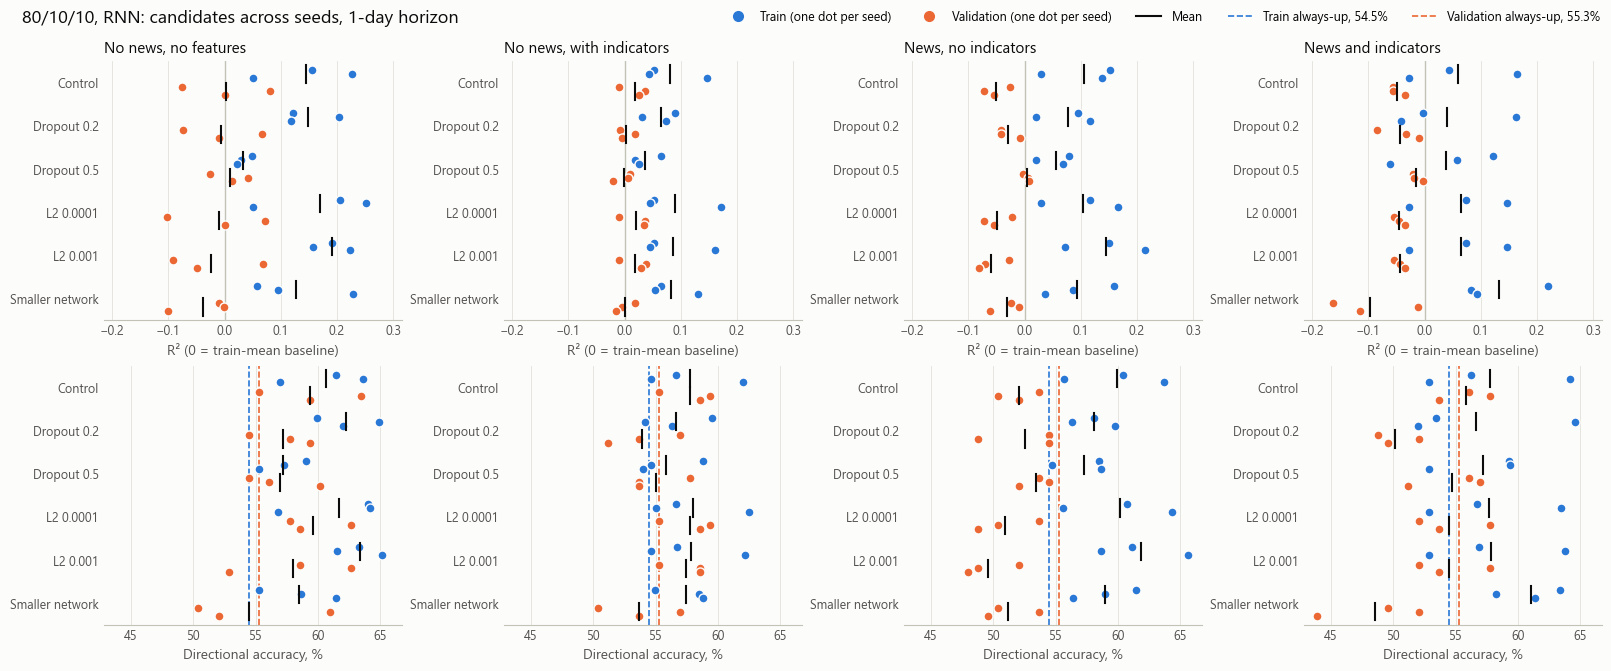

In [15]:
plot_split_results(
    for_base_model(split_metrics, "RNN"),
    r2_limits=(-0.2, 0.3),
    title="80/10/10, RNN: candidates across seeds, 1-day horizon",
)

### 80/10/10: LSTM candidates

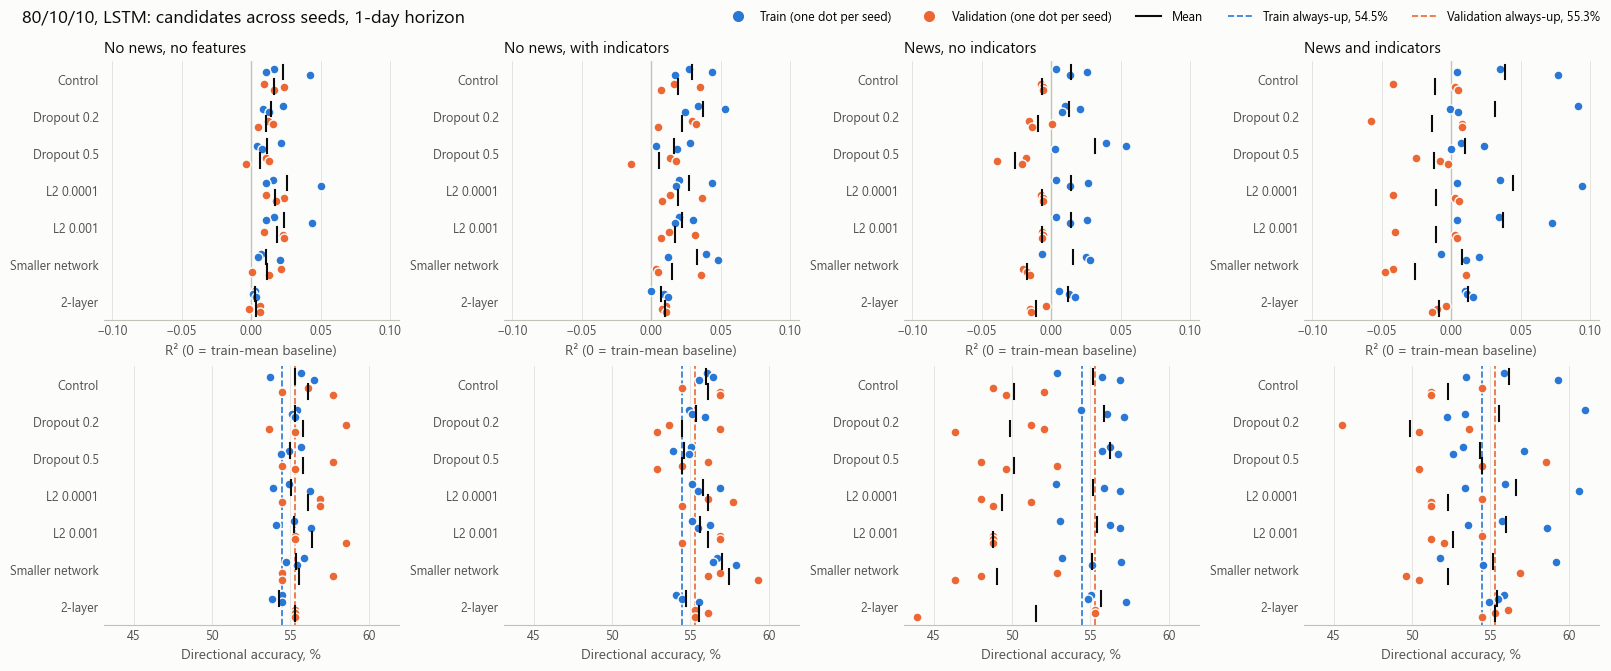

In [16]:
plot_split_results(
    for_base_model(split_metrics, "LSTM"),
    r2_limits=(-0.1, 0.1),
    title="80/10/10, LSTM: candidates across seeds, 1-day horizon",
)

### 80/10/10: XGBoost candidates

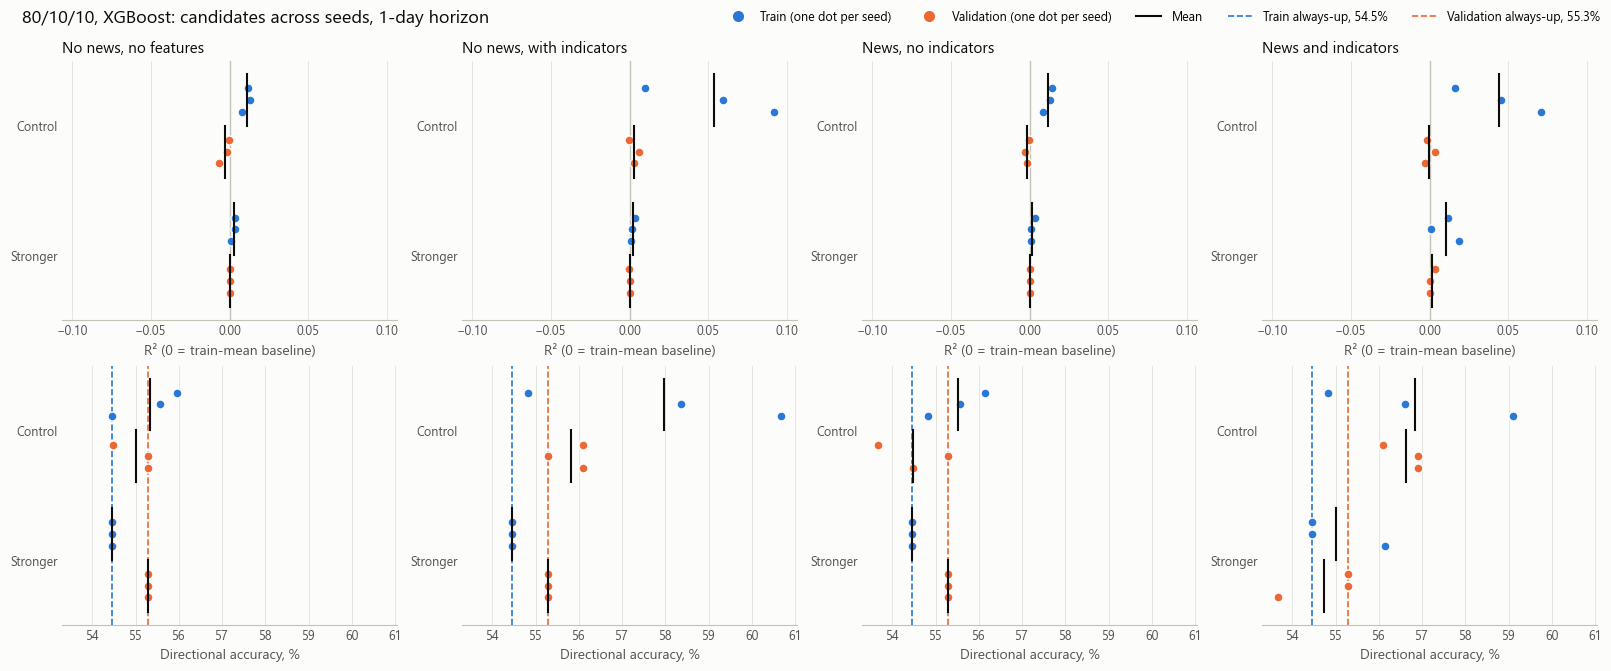

In [17]:
plot_split_results(
    for_base_model(split_metrics, "XGBoost"),
    r2_limits=(-0.1, 0.1),
    title="80/10/10, XGBoost: candidates across seeds, 1-day horizon",
)

### 80/10/10: summary table

In [18]:
table = split_metrics.assign(oos_r2=1 - split_metrics["mse"] / split_metrics["baseline_mse"])
table.pivot_table(index=["track", "model"], columns="split", values=["oos_r2", "directional_accuracy"], sort=False)

oos_r2            directional_accuracy           
split                                                          train validation                train validation
track                                  model                                                                   
no_news_no_feature_engineering         RNN | Control          0.1442     0.0022               0.6066     0.5935
                                       LSTM | Control         0.0233     0.0164               0.5530     0.5610
                                       XGBoost | Control      0.0109    -0.0028               0.5533     0.5501
                                       RNN | Dropout 0.2      0.1479    -0.0054               0.6227     0.5718
                                       RNN | Dropout 0.5      0.0336     0.0096               0.5719     0.5691
                                       RNN | L2 0.0001        0.1692    -0.0101               0.6165     0.5962
                                       RNN | L2 0.001         0.1907    -0.0244               0.6332     0.5799
                                       RNN | Smaller network  0.1271    -0.0375               0.5846     0.5447
                                       LSTM | Dropout 0.2     0.0146     0.0109               0.5527     0.5583
                                       LSTM | Dropout 0.5     0.0112     0.0067               0.5499     0.5583
                                       LSTM | L2 0.0001       0.0257     0.0172               0.5502     0.5610
                                       LSTM | L2 0.001        0.0235     0.0187               0.5520     0.5637
                                       LSTM | Smaller network 0.0111     0.0115               0.5533     0.5556
                                       LSTM | 2-layer         0.0027     0.0037               0.5424     0.5528
                                       XGBoost | Stronger     0.0027     0.0002               0.5446     0.5528
no_news_with_feature_engineering       RNN | Control          0.0812     0.0178               0.5774     0.5772
                                       LSTM | Control         0.0295     0.0196               0.5601     0.5610
                                       XGBoost | Control      0.0536     0.0029               0.5796     0.5583
                                       RNN | Dropout 0.2      0.0650     0.0020               0.5666     0.5393
                                       RNN | Dropout 0.5      0.0363    -0.0017               0.5582     0.5501
                                       RNN | L2 0.0001        0.0896     0.0205               0.5802     0.5772
                                       RNN | L2 0.001         0.0860     0.0192               0.5784     0.5745
                                       RNN | Smaller network  0.0832     0.0001               0.5740     0.5366
                                       LSTM | Dropout 0.2     0.0371     0.0222               0.5533     0.5447
                                       LSTM | Dropout 0.5     0.0168     0.0058               0.5462     0.5447
                                       LSTM | L2 0.0001       0.0270     0.0194               0.5582     0.5610
                                       LSTM | L2 0.001        0.0224     0.0173               0.5561     0.5610
                                       LSTM | Smaller network 0.0332     0.0148               0.5700     0.5745
                                       LSTM | 2-layer         0.0073     0.0099               0.5471     0.5556
                                       XGBoost | Stronger     0.0020     0.0002               0.5446     0.5528
news_with_feature_engineering          RNN | Control          0.1061    -0.0505               0.5991     0.5203
                                       LSTM | Control         0.0145    -0.0064               0.5517     0.5014
                                       XGBoost | Control      0.0117    -0.0016               0.5551     0.5447
                              

## Conclusions

**No candidate met the progress criteria, so there's no winner and no 5-seed rerun.** On walk-forward, no seed of any setup beat the train-mean baseline on MSE, and every setup averaged below always-up on direction.

- **Better scores came from flatter predictions.** Across the 60 setups, the narrower the predictions, the better the R² (rank correlation -0.91).
- **Stronger XGBoost is close to predicting the mean.** It has the best R², -0.0006 (-0.0043 to 0.0031) with no news and no features, but its spread is 0.05 of actual, about 92% of its predictions are up, and its correlation is at or below zero.
- **A weak lead in the RNNs.** 9 of 60 correlation intervals are above zero, and all 9 are RNNs. The best control is no news with indicators, at 0.087 (0.021 to 0.156). It's still below the baseline, and it was picked from 60 setups.
- **News never helped.** In the 15 news against no news comparisons, it was never better on MSE or direction. It was worse on MSE in 7 and worse on direction in 1. The control's results differ from the 5-seed run, so individual results depend on the seeds.
- **80/10/10 agrees on news.** 19 of the 20 best setups have no news. The best has an R² of 0.022, with direction at 54.5% against 55.3% for always-up.